<a href="https://colab.research.google.com/github/Uwimpaye-yve/african-nlp-text-classification/blob/main/afrisenti_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q transformers datasets accelerate evaluate scikit-learn seaborn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.8 MB/s eta 0:00:00


In [ ]:
from datasets import load_dataset

LANG = "swa"
print(f"Loading MasakhaNEWS benchmark for language: {LANG}...")
dataset = load_dataset("masakhane/masakhanews", LANG)

print("\n--- Dataset Overview ---")
print(dataset)

Loading MasakhaNEWS benchmark for language: swa...


README.md:   0%|          | 0.00/10.7k [00:00<?, ?B/s]

train.tsv:   0%|          | 0.00/6.25M [00:00<?, ?B/s]

dev.tsv:   0%|          | 0.00/859k [00:00<?, ?B/s]

test.tsv:   0%|          | 0.00/1.76M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1658 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/237 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/476 [00:00<?, ? examples/s]


--- Dataset Overview ---
DatasetDict({
    train: Dataset({
        features: ['category', 'headline', 'text', 'url'],
        num_rows: 1658
    })
    validation: Dataset({
        features: ['category', 'headline', 'text', 'url'],
        num_rows: 237
    })
    test: Dataset({
        features: ['category', 'headline', 'text', 'url'],
        num_rows: 476
    })
})


Total categories (7): ['business', 'entertainment', 'health', 'politics', 'religion', 'sports', 'technology']

--- Class Counts (Train Split) ---
category
sports           350
health           350
politics         350
business         221
religion         204
technology       115
entertainment     68
Name: count, dtype: int64


/tmp/ipykernel_3406/3977591875.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x="category", order=train_df["category"].value_counts().index, palette="mako")


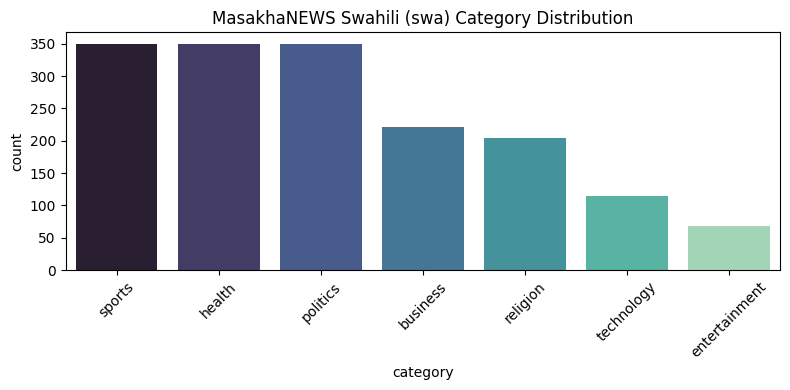

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Convert Hugging Face splits to Pandas DataFrames
train_df = pd.DataFrame(dataset["train"])
val_df = pd.DataFrame(dataset["validation"])
test_df = pd.DataFrame(dataset["test"])

# 2. Extract and map target categories
categories = sorted(train_df["category"].unique())
label2id = {cat: i for i, cat in enumerate(categories)}
id2label = {i: cat for i, cat in enumerate(categories)}

train_df["label"] = train_df["category"].map(label2id)
val_df["label"] = val_df["category"].map(label2id)
test_df["label"] = test_df["category"].map(label2id)

# 3. Concatenate headline and full article text for feature representation
train_df["input_text"] = train_df["headline"].fillna("") + " " + train_df["text"].fillna("")
val_df["input_text"] = val_df["headline"].fillna("") + " " + val_df["text"].fillna("")
test_df["input_text"] = test_df["headline"].fillna("") + " " + test_df["text"].fillna("")

print(f"Total categories ({len(categories)}): {categories}")
print("\n--- Class Counts (Train Split) ---")
print(train_df["category"].value_counts())

# 4. Plot distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=train_df, x="category", order=train_df["category"].value_counts().index, palette="mako")
plt.title(f"MasakhaNEWS Swahili (swa) Category Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

BASELINE EVALUATION: TF-IDF + Logistic Regression
               precision    recall  f1-score   support

     business       0.71      0.75      0.73        64
entertainment       0.67      0.30      0.41        20
       health       0.74      0.93      0.83       100
     politics       0.78      0.84      0.81       100
     religion       0.88      0.73      0.80        59
       sports       1.00      0.91      0.95       100
   technology       0.85      0.67      0.75        33

     accuracy                           0.81       476
    macro avg       0.80      0.73      0.75       476
 weighted avg       0.82      0.81      0.81       476

Baseline Test Accuracy: 0.8130
Baseline Test Macro F1: 0.7529


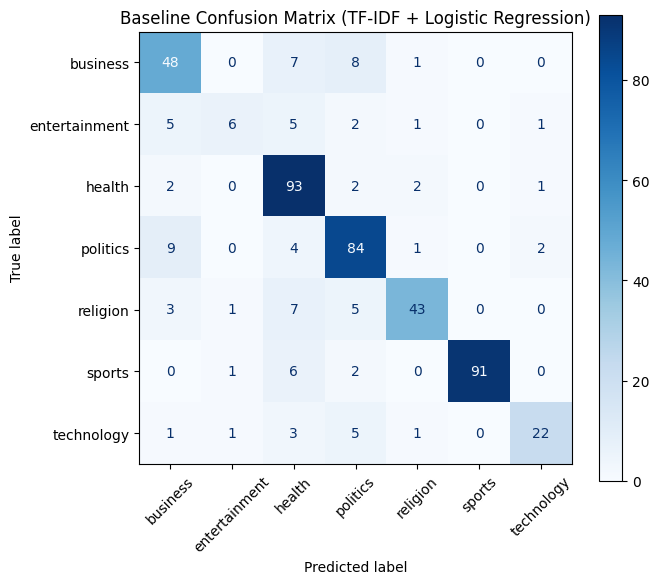

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Features and targets
X_train, y_train = train_df["input_text"], train_df["label"]
X_test, y_test = test_df["input_text"], test_df["label"]

# Fit n-gram TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

# Train Logistic Regression
baseline_model = LogisticRegression(max_iter=1000, C=1.0)
baseline_model.fit(X_train_vec, y_train)

# Evaluate on test set
baseline_preds = baseline_model.predict(X_test_vec)
target_names = [id2label[i] for i in range(len(categories))]

print("=" * 65)
print("BASELINE EVALUATION: TF-IDF + Logistic Regression")
print("=" * 65)
print(classification_report(y_test, baseline_preds, target_names=target_names))

baseline_acc = accuracy_score(y_test, baseline_preds)
baseline_f1 = f1_score(y_test, baseline_preds, average="macro")
print(f"Baseline Test Accuracy: {baseline_acc:.4f}")
print(f"Baseline Test Macro F1: {baseline_f1:.4f}")

# Plot baseline confusion matrix
cm_baseline = confusion_matrix(y_test, baseline_preds)
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_baseline, display_labels=target_names)
disp.plot(cmap="Blues", ax=ax, xticks_rotation=45)
plt.title("Baseline Confusion Matrix (TF-IDF + Logistic Regression)")
plt.tight_layout()
plt.show()

In [ ]:
import torch
from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)
import evaluate

MODEL_CHECKPOINT = "castorini/afriberta_small"
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

# Prepare Hugging Face dataset format
hf_dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df[["input_text", "label"]].rename(columns={"label": "labels"})),
    "validation": Dataset.from_pandas(val_df[["input_text", "label"]].rename(columns={"label": "labels"})),
    "test": Dataset.from_pandas(test_df[["input_text", "label"]].rename(columns={"label": "labels"}))
})

# Tokenize text inputs
def tokenize_batch(batch):
    return tokenizer(batch["input_text"], truncation=True, max_length=256)

tokenized_datasets = hf_dataset.map(tokenize_batch, batched=True)

# Metrics for Trainer
f1_metric = evaluate.load("f1")
acc_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    f1 = f1_metric.compute(predictions=preds, references=labels, average="macro")["f1"]
    acc = acc_metric.compute(predictions=preds, references=labels)["accuracy"]
    return {"accuracy": acc, "macro_f1": f1}

# Load model weights
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=len(categories),
    id2label=id2label,
    label2id=label2id
)

# Training configurations
training_args = TrainingArguments(
    output_dir="./afriberta_masakhanews",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=3e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=4,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    logging_steps=25,
    save_total_limit=1,
    report_to="none"
)

# Trainer initialization
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics,
)

# Start fine-tuning
trainer.train()

Map:   0%|          | 0/1658 [00:00<?, ? examples/s]

Map:   0%|          | 0/237 [00:00<?, ? examples/s]

Map:   0%|          | 0/476 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/69 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: castorini/afriberta_small
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=416, training_loss=0.3848918229341507, metrics={'train_runtime': 259.8083, 'train_samples_per_second': 25.527, 'train_steps_per_second': 1.601, 'total_flos': 294896273461248.0, 'train_loss': 0.3848918229341507, 'epoch': 4.0})

AFRIBERTA EVALUATION ON TEST SET
               precision    recall  f1-score   support

     business       0.75      0.78      0.76        64
entertainment       0.80      0.80      0.80        20
       health       0.86      0.89      0.88       100
     politics       0.87      0.88      0.88       100
     religion       0.93      0.85      0.88        59
       sports       0.97      0.97      0.97       100
   technology       0.77      0.73      0.75        33

     accuracy                           0.87       476
    macro avg       0.85      0.84      0.85       476
 weighted avg       0.87      0.87      0.87       476


--- PERFORMANCE COMPARISON TABLE ---
Model                               | Accuracy   | Macro F1  
-----------------------------------------------------------------
TF-IDF + Logistic Regression (Baseline) | 0.8130     | 0.7529    
Fine-Tuned AfriBERTa                | 0.8697     | 0.8458    


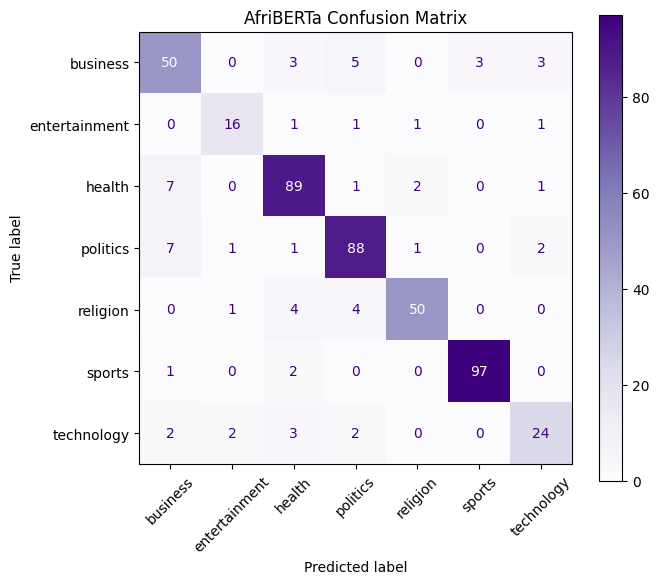


--- SAMPLE ERROR ANALYSIS EXAMPLES ---

Headline: Siku 100 za utawala wa Ruto: Uzito kwa rais wa Kenya kuambatanisha maneno na vitendo
Ground Truth: business | Predicted: politics

Headline: Virusi vya corona: Kwa nini watoto waliozaliwa na kina mama wa kupanga wamekwama Ukraine?
Ground Truth: business | Predicted: health

Headline: Kwanini Michael Jordan hawezi kuuza jumba lake la kifahari kwa $29m
Ground Truth: business | Predicted: sports

Headline: Marekani yazindua makombora ya  hypersonic  kwa mara ya kwanza. Je hii ni silaha gani?
Ground Truth: business | Predicted: technology

Headline: 'Muujiza' wa Qatar: Mabadiliko yaliyoifanya nchi hii  kuwa moja ya mataifa tajiri zaidi duniani
Ground Truth: business | Predicted: sports


In [ ]:
# Predict on test split
test_predictions = trainer.predict(tokenized_datasets["test"])
test_preds = np.argmax(test_predictions.predictions, axis=-1)
test_true = test_df["label"].values

print("=" * 65)
print("AFRIBERTA EVALUATION ON TEST SET")
print("=" * 65)
print(classification_report(test_true, test_preds, target_names=target_names))

afri_acc = accuracy_score(test_true, test_preds)
afri_f1 = f1_score(test_true, test_preds, average="macro")

print("\n--- PERFORMANCE COMPARISON TABLE ---")
print(f"{'Model':<35} | {'Accuracy':<10} | {'Macro F1':<10}")
print("-" * 65)
print(f"{'TF-IDF + Logistic Regression (Baseline)':<35} | {baseline_acc:<10.4f} | {baseline_f1:<10.4f}")
print(f"{'Fine-Tuned AfriBERTa':<35} | {afri_acc:<10.4f} | {afri_f1:<10.4f}")

# Plot confusion matrix
cm_transformer = confusion_matrix(test_true, test_preds)
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_transformer, display_labels=target_names)
disp.plot(cmap="Purples", ax=ax, xticks_rotation=45)
plt.title("AfriBERTa Confusion Matrix")
plt.tight_layout()
plt.show()

# Extract failure cases for Error Analysis section
test_df["predicted_label"] = [id2label[p] for p in test_preds]
test_df["ground_truth"] = [id2label[t] for t in test_true]
failure_cases = test_df[test_df["predicted_label"] != test_df["ground_truth"]].head(5)

print("\n--- SAMPLE ERROR ANALYSIS EXAMPLES ---")
for idx, row in failure_cases.iterrows():
    print(f"\nHeadline: {row['headline']}")
    print(f"Ground Truth: {row['ground_truth']} | Predicted: {row['predicted_label']}")

In [ ]:
# Save weights and tokenizer
model.save_pretrained("./best_afriberta_model")
tokenizer.save_pretrained("./best_afriberta_model")

# Package into zip file for easy download
!zip -r best_afriberta_model.zip best_afriberta_model/

from google.colab import files
files.download("best_afriberta_model.zip")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  adding: best_afriberta_model/ (stored 0%)
  adding: best_afriberta_model/model.safetensors (deflated 8%)
  adding: best_afriberta_model/tokenizer.json (deflated 77%)
  adding: best_afriberta_model/config.json (deflated 54%)
  adding: best_afriberta_model/tokenizer_config.json (deflated 50%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>